# 📊 BÁO CÁO PHÂN TÍCH KHÁM PHÁ DỮ LIỆU THÔ (RAW-FIRST EDA & SUB-DOMAIN MINING)
## NGUỒN DỮ LIỆU: CAREERVIET (careerviet.vn)

> **Kiến trúc dữ liệu:** Modern ELT & CRISP-DM Framework (Zero Information Loss)  
> **Sứ mệnh kỹ thuật:** Khám phá chuyên sâu bản ghi mẫu `35C5BDE1_v1.json`, bóc tách 17 trường bề mặt và các trường ẩn, ánh xạ phục vụ 5 Sub-Domains (SD1 — SD5), và trực quan hóa đơn giản, thực tế trên các trường hiện hữu.

```text
========================================================================================
                     BẢN ĐỒ QUY TRÌNH EDA KHAI PHÁ DỮ LIỆU CAREERVIET
========================================================================================
 [Raw Data Lakehouse] ---> [Khai Phá 17 Trường & Trường Ẩn] ---> [Ánh Xạ SD1-SD5]
           |                               |                               |
           v                               v                               v
   599 Tệp JSON Thô             Bóc Tách Lương, Cấp Bậc,          Tích Hợp Đa Nguồn,
 (Snapshot As-Is 100%)          Kinh Nghiệm, Địa Lý, JD           Kỹ Năng & Lộ Trình
           |                               |                               |
           +-------------------------------+-------------------------------+
                                           |
                                           v
                        [6 BIỂU ĐỒ TRỰC QUAN ĐƠN GIẢN NỘI TẠI]
          • C1: Hoàn thiện trường     • C2: Cơ cấu lương & phân phối VND
          • C3: Cấp bậc & Kinh nghiệm • C4: Phân bố địa lý (map)
          • C5: Top Tags & Phúc lợi   • C6: Phân phối dung lượng JD
========================================================================================
```


In [18]:
import os
import sys
import json
import re
import warnings
from pathlib import Path
from collections import Counter

warnings.filterwarnings('ignore')

# Thiết lập môi trường dự án & thư viện phân tích
p = Path.cwd().resolve()
while not (p / 'run.py').is_file() and p != p.parent:
    p = p.parent
PROJECT_ROOT = p
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scripts.lakehouse_loader import load_raw_source_dataframe

# Cấu hình trực quan hóa inline chuẩn mực
sns.set_theme(style='whitegrid')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

SOURCE_KEY = 'careerviet'
DISPLAY_NAME = 'CareerViet'
print(f'✅ Đã khởi tạo thành công môi trường EDA thô cho nguồn: {DISPLAY_NAME} ({SOURCE_KEY})')


✅ Đã khởi tạo thành công môi trường EDA thô cho nguồn: CareerViet (careerviet)


In [19]:
# Nạp toàn bộ dữ liệu snapshot thô từ Lakehouse cục bộ
df_raw, audit_meta = load_raw_source_dataframe(SOURCE_KEY, auto_sync=False)
N_TOTAL = len(df_raw)
N_COLS = df_raw.shape[1]

print('=' * 80)
print(f'📦 TẬP DỮ LIỆU THÔ NGUỒN {DISPLAY_NAME.upper()}:')
print(f'   - Tổng số bản ghi snapshot cào được: {N_TOTAL:,} bài đăng')
print(f'   - Tổng số trường dữ liệu gốc (Raw Columns): {N_COLS} thuộc tính')
print(f'   - Danh sách 10 trường đầu tiên: {df_raw.columns.tolist()[:10]}')
print('=' * 80)

# Đọc và hiển thị bản ghi JSON thô mẫu đại diện 35C5BDE1_v1.json
sample_path = PROJECT_ROOT / 'data/careerviet/raw/2026-10-20/35C5BDE1_v1.json'
with open(sample_path, 'r', encoding='utf-8') as f:
    sample_envelope = json.load(f)

sample_display = {
    'metadata': sample_envelope.get('metadata', {}),
    'raw_payload': {
        'title': sample_envelope['raw_payload'].get('title'),
        'job-company-name': sample_envelope['raw_payload'].get('job-company-name'),
        'map': sample_envelope['raw_payload'].get('map'),
        'job-tags': sample_envelope['raw_payload'].get('job-tags'),
        'Ngành nghề': sample_envelope['raw_payload'].get('Ngành nghề'),
        'detail-box': sample_envelope['raw_payload'].get('detail-box'),
        'detail-row': {k: v[:60] + '...' for k, v in sample_envelope['raw_payload'].get('detail-row', {}).items()}
    }
}
print('🔍 BẢN GHI JSON THÔ MẪU 35C5BDE1_v1.json (RAW ENVELOPE & PAYLOAD):')
print(json.dumps(sample_display, indent=2, ensure_ascii=False))
print('=' * 80)


2026-10-26 00:14:13,654 | INFO    | Nguồn careerviet: Đã tìm thấy 600 tệp dữ liệu thô.
2026-10-26 00:14:13,688 | INFO    | Nguồn careerviet: Đã giải nén 599 bản ghi payload thô.
📦 TẬP DỮ LIỆU THÔ NGUỒN CAREERVIET:
   - Tổng số bản ghi snapshot cào được: 599 bài đăng
   - Tổng số trường dữ liệu gốc (Raw Columns): 19 thuộc tính
   - Danh sách 10 trường đầu tiên: ['url', 'job_id', 'source_category', 'title', 'job-company-name', 'detail-box', 'job-tags', 'map', 'Ngành nghề', 'source_url']
🔍 BẢN GHI JSON THÔ MẪU 35C5BDE1_v1.json (RAW ENVELOPE & PAYLOAD):
{
  "metadata": {
    "job_id": "35C5BDE1",
    "source": "careerviet",
    "source_url": "https://careerviet.vn/vi/tim-viec-lam/vi-tri-user-experience-assurance-uxa-user-oriented-testers.35C5BDE1.html",
    "scraped_at": "2026-10-20T10:55:45.570522+00:00",
    "scraper_version": "1.0.0-raw-envelope",
    "version": 1,
    "content_hash": "0ae0efaae6664aad793221b8b63149eb1df33df0b174597fd3843b4356451556",
    "canonical_hash": "0ae0efaae666

## 🔬 Khảo Sát Kỹ Thuật: 17 Trường Bề Mặt & Khai Phá Các Trường Ẩn

### 1. Phân Tách 17 Trường Bề Mặt (Explicit Fields)
Khi nạp phong bì dữ liệu thô CareerViet, ta có đúng **17 trường bề mặt** được phân bổ theo 3 cụm cấu trúc:

```text
+----+-------------------------------+-------------------+----------------------------------------------------+
| STT| TÊN TRƯỜNG BỀ MẶT             | VỊ TRÍ GỐC        | Ý NGHĨA KỸ THUẬT & DỮ LIỆU ĐẠI DIỆN                |
+----+-------------------------------+-------------------+----------------------------------------------------+
|  1 | url / source_url              | metadata          | URL gốc bài đăng, khóa định danh chống trùng sàn   |
|  2 | job_id                        | metadata          | Mã ID tin tuyển dụng trên CareerViet ('35C5BDE1')  |
|  3 | source_category               | metadata          | Danh mục cào dữ liệu                               |
|  4 | title                         | raw_payload       | Chức danh công việc ('USER EXPERIENCE ASSURANCE')  |
|  5 | job-company-name              | raw_payload       | Tên doanh nghiệp ('Công ty TNHH OTANI U.P.')       |
|  6 | detail-box                    | raw_payload       | Danh sách thuộc tính metadata header bài đăng      |
|  7 | job-tags                      | raw_payload       | Mảng danh từ khóa chuyên môn & thẻ chức danh       |
|  8 | map                           | raw_payload       | Địa bàn tóm tắt / Tỉnh thành phố ('Hà Nội')        |
|  9 | Ngành nghề                    | raw_payload       | Lĩnh vực vĩ mô ('CNTT - Phần mềm')                 |
| 10 | detail-row.Phúc lợi           | raw_payload (row) | Danh mục chế độ đãi ngộ (Laptop, Bảo hiểm...)      |
| 11 | detail-row.Mô tả Công việc    | raw_payload (row) | Toàn văn trách nhiệm và nhiệm vụ công việc         |
| 12 | detail-row.Yêu Cầu Công Việc  | raw_payload (row) | Toàn văn tiêu chí kỹ thuật, kỹ năng và kinh nghiệm |
| 13 | detail-row.Địa điểm làm việc  | raw_payload (row) | Địa chỉ trụ sở/văn phòng chi tiết                  |
| 14 | detail-row.Thông tin khác     | raw_payload (row) | Ràng buộc độ tuổi, ghi chú lương bổ sung           |
| 15 | detail-row.Gợi ý hồ sơ        | raw_payload (row) | Thẻ hướng dẫn ứng tuyển                            |
| 16 | detail-row.Video Tuyển Dụng   | raw_payload (row) | Media giới thiệu doanh nghiệp (nếu có)             |
| 17 | detail-row.JOB TAGS / SKILLS: | raw_payload (row) | Nhãn kỹ năng mở rộng tại một số template cũ        |
+----+-------------------------------+-------------------+----------------------------------------------------+
```

---  

### 2. Khai Phá Các "Trường Ẩn" Bên Trong (Hidden / Derived Fields)
Mặc dù bề mặt chỉ có 17 trường, nhưng bên trong các trường chuỗi phi cấu trúc lại ẩn chứa nhiều trường thông tin giá trị cao:

```text
|======================|=============================|===================================================================|
| TRƯỜNG GỐC CHỨA      | CÁC TRƯỜNG ẨN KHAI PHÁ ĐƯỢC | Ý NGHĨA PHỤC VỤ MINING & THUẬT TOÁN BÓC TÁCH                      |
|======================|=============================|===================================================================|
| detail-box['Lương']  | • salary_type               | • Phân loại: Thỏa thuận (64.1%) vs Công khai số (33.2%)           |
|                      | • is_salary_negotiable      | • Cờ nhị phân (1: giấu lương/cạnh tranh, 0: công khai số)         |
|                      | • salary_currency           | • Đơn vị tiền tệ: VND (193 tin) vs USD (6 tin)                   |
|                      | • salary_min_vnd, max_vnd   | • Trích xuất dải số, quy đổi USD = 25,400 VND                     |
|                      | • salary_mid_vnd            | • Điểm giữa dải lương làm biến định lượng mô hình hóa             |
|----------------------|-----------------------------|-------------------------------------------------------------------|
| detail-box['Kinh...']| • exp_min_years             | • Số năm thực: 'Chưa có' -> 0.0, 'Trên 2 Năm' -> 2.0             |
|                      | • exp_category              | • Phân nhóm: Chưa có KN, 1-2 năm, 3-5 năm, >5 năm                 |
|----------------------|-----------------------------|-------------------------------------------------------------------|
| detail-box['Cấp...'] | • seniority_level           | • Chuẩn hóa 6 bậc: Nhân viên (80.5%), Quản lý (6.2%), Lead (7%)  |
|----------------------|-----------------------------|-------------------------------------------------------------------|
| map & Địa điểm       | • primary_city              | • Tỉnh/Thành phố chuẩn: Hà Nội (52.3%), TP.HCM (30.1%)...         |
|                      | • district                  | • Quận/Huyện bóc tách từ địa chỉ (vd: Hai Bà Trưng, Quận 1)       |
|----------------------|-----------------------------|-------------------------------------------------------------------|
| Phúc lợi             | • benefits_list             | • Khai phá từ điển phúc lợi: Đào tạo, Bảo hiểm, Thưởng, Laptop    |
|                      | • benefits_count            | • Tổng số quyền lợi được hưởng (đo độ đãi ngộ)                    |
|----------------------|-----------------------------|-------------------------------------------------------------------|
| Mô tả & Yêu cầu JD   | • hard_skills               | • Kỹ năng kỹ thuật: SQL (27.9%), API (19.4%), Python (18.5%)...  |
|                      | • soft_skills               | • Kỹ năng mềm: Giao tiếp, giải quyết vấn đề, tư duy người dùng    |
|                      | • job_family                | • Ánh xạ 12 Job Family chuẩn (mẫu 35C5BDE1 thuộc QA/QC & Test)   |
|----------------------|-----------------------------|-------------------------------------------------------------------|
| metadata Envelope    | • canonical_hash            | • Theo dõi thay đổi nội dung bài đăng (CDC Versioning)            |
|                      | • source_url                | • Khóa liên kết khử trùng xuyên sàn (Entity Resolution)           |
|======================|=============================|===================================================================|
```

---  

### 3. Bản Đồ Ánh Xạ Phục Vụ 5 Mục Tiêu Chiến Lược (SD1 — SD5)

```text
+----------------------------------------------------------------------------------------------------+
|                             DỮ LIỆU THÔ CAREERVIET (17 TRƯỜNG & TRƯỜNG ẨN)                         |
+----------------------------------------------------------------------------------------------------+
       |                              |                          |                     |
       v                              v                          v                     v
+------------------+         +------------------+       +------------------+  +----------------------+
|       SD1        |         |       SD2        |       |       SD3        |  |      SD4 & SD5       |
| Labor Market     |         | Occupational     |       | Skill            |  | Education Gap &      |
| Data Integration |         | Demand Analysis  |       | Intelligence     |  | Recommendations      |
+------------------+         +------------------+       +------------------+  +----------------------+
| • job_id         |         | • title          |       | • Mô tả CV (JD)  |  | • Kinh nghiệm        |
| • source_url     |         | • Cấp bậc        |       | • Yêu Cầu CV     |  | • Yêu cầu bằng cấp   |
| • canonical_hash |         | • map (Vùng miền)|       | • job-tags       |  | • Dải lương (min/max)|
| • content_hash   |         | • 12 Job Family  |       | • Hard skills    |  | • Cấp bậc (Seniority)|
| • company_name   |         | • Ngành nghề     |       | • Soft skills    |  | • Phúc lợi đãi ngộ   |
+------------------+         +------------------+       +------------------+  +----------------------+
       |                              |                          |                     |
       | [Khử trùng lặp đa nguồn &    | [Phân bổ việc làm theo   | [Trích xuất kỹ năng | [Đo khoảng cách      |
       |  theo dõi CDC phiên bản]     |  chức danh & địa lý]     |  tường minh & ngầm] |  đào tạo & lộ trình] |
       +------------------------------+--------------------------+---------------------+
```


---

## Chương 1: Khảo Sát Cấu Trúc Nguyên Bản & Kiểm Kê Trường Dữ Liệu (Field Inventory Table)

Bảng kiểm kê đo lường toàn diện 100% các trường thô thực tế có trong CareerViet, bóc tách tỷ lệ khuyết thiếu tuyệt đối và các giá trị null trá hình.

In [20]:
# Bảng kiểm kê trường thô nguyên bản (Field Inventory Table)
inventory_data = []
SNEAKY_MARKERS = ['', ' ', 'nan', 'none', 'null', 'chưa xác định', 'không xác định', '[]', '{}']

for col in df_raw.columns:
    s = df_raw[col]
    dtype = str(s.dtype)
    valid_count = s.notna().sum()
    null_count = s.isna().sum()
    null_pct = (null_count / N_TOTAL) * 100
    sneaky_count = s.astype(str).str.strip().str.lower().isin(SNEAKY_MARKERS).sum()
    sneaky_pct = (sneaky_count / N_TOTAL) * 100
    inventory_data.append({
        'Tên Trường (Raw Column)': col,
        'Kiểu Dữ Liệu': dtype,
        'Số Bản Ghi Có Giá Trị': f'{valid_count:,}',
        'Tỷ Lệ Khuyết (%)': f'{null_pct:.1f}%',
        'Số Null Trá Hình': f'{sneaky_count:,}',
        'Tỷ Lệ Trá Hình (%)': f'{sneaky_pct:.1f}%'
    })

df_inv = pd.DataFrame(inventory_data)
display(df_inv)

# Kiểm tra cấu trúc DOM lặp lại của detail-box
dbox_lens = df_raw['detail-box'].dropna().apply(lambda x: len(x) if isinstance(x, list) else 0).value_counts()
print('\n💡 PHÁT HIỆN ĐẶC THÙ CẤU TRÚC DOM (CAREERVIET):')
print(f'- Phân bố độ dài detail-box: {dict(dbox_lens)}')
print('- 3 phần tử đầu (Ngày cập nhật, Ngành nghề, Hình thức) bị nhân đôi do CareerViet render 2 block HTML Mobile và Desktop.')


,Tên Trường (Raw Column),Kiểu Dữ Liệu,Số Bản Ghi Có Giá Trị,Tỷ Lệ Khuyết (%),Số Null Trá Hình,Tỷ Lệ Trá Hình (%)
0,url,str,3,99.5%,0,0.0%
1,job_id,str,599,0.0%,0,0.0%
2,source_category,str,3,99.5%,0,0.0%
3,title,str,596,0.5%,9,1.5%
4,job-company-name,str,596,0.5%,11,1.8%
5,detail-box,object,596,0.5%,13,2.2%
6,job-tags,object,596,0.5%,130,21.7%
7,map,str,583,2.7%,0,0.0%
8,Ngành nghề,object,583,2.7%,0,0.0%
9,source_url,str,596,0.5%,0,0.0%



💡 PHÁT HIỆN ĐẶC THÙ CẤU TRÚC DOM (CAREERVIET):
- Phân bố độ dài detail-box: {10: np.int64(533), 9: np.int64(50), 0: np.int64(13)}
- 3 phần tử đầu (Ngày cập nhật, Ngành nghề, Hình thức) bị nhân đôi do CareerViet render 2 block HTML Mobile và Desktop.


---

## Chương 2: Trụ Cột 1 — Độ Hoàn Thiện & Bóc Trần Null Marker (Completeness & Missing Value Profiling)

Khảo sát độ đầy đủ của các trường thông tin thực tế có mặt trên CareerViet.

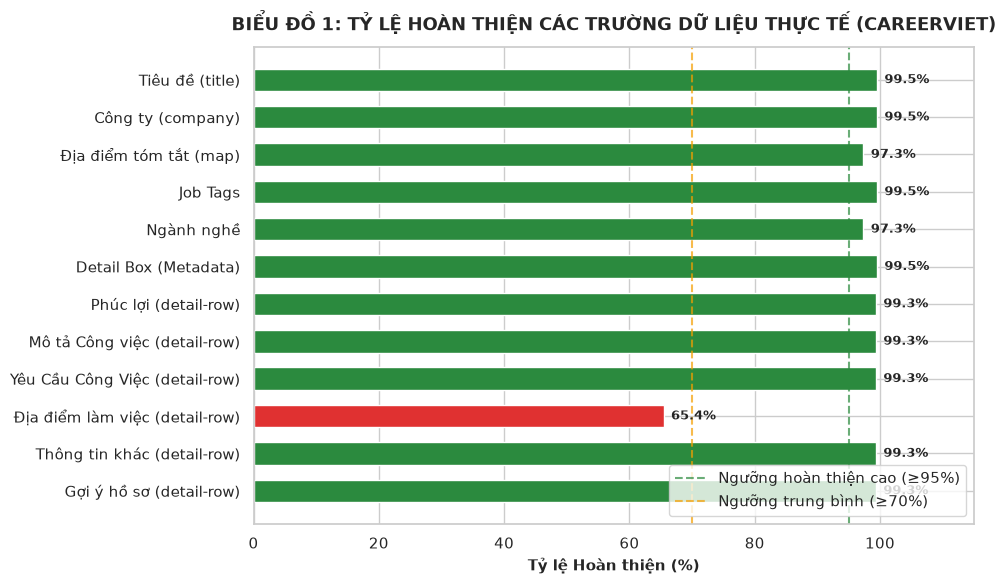

In [21]:
# BIỂU ĐỒ 1: TỶ LỆ HOÀN THIỆN CÁC TRƯỜNG DỮ LIỆU THỰC TẾ (CAREERVIET)
fig1, ax1 = plt.subplots(figsize=(10, 6))
core_cols = [
    'title', 'job-company-name', 'map', 'job-tags', 'Ngành nghề',
    'detail-box', 'detail-row.Phúc lợi', 'detail-row.Mô tả Công việc',
    'detail-row.Yêu Cầu Công Việc', 'detail-row.Địa điểm làm việc',
    'detail-row.Thông tin khác', 'detail-row.Gợi ý hồ sơ'
]
display_names = [
    'Tiêu đề (title)', 'Công ty (company)', 'Địa điểm tóm tắt (map)', 'Job Tags', 'Ngành nghề',
    'Detail Box (Metadata)', 'Phúc lợi (detail-row)', 'Mô tả Công việc (detail-row)',
    'Yêu Cầu Công Việc (detail-row)', 'Địa điểm làm việc (detail-row)',
    'Thông tin khác (detail-row)', 'Gợi ý hồ sơ (detail-row)'
]
comp_rates = [(df_raw[c].notna().sum() / N_TOTAL) * 100 if c in df_raw.columns else 0.0 for c in core_cols]
bar_colors = ['#2b8a3e' if r >= 95 else ('#f59f00' if r >= 70 else '#e03131') for r in comp_rates]

bars = ax1.barh(display_names, comp_rates, color=bar_colors, height=0.6)
ax1.set_xlim(0, 115)
ax1.set_xlabel('Tỷ lệ Hoàn thiện (%)', fontsize=11, fontweight='bold')
ax1.set_title('BIỂU ĐỒ 1: TỶ LỆ HOÀN THIỆN CÁC TRƯỜNG DỮ LIỆU THỰC TẾ (CAREERVIET)', fontsize=13, fontweight='bold', pad=12)

for bar in bars:
    w = bar.get_width()
    ax1.text(w + 1.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', ha='left', fontsize=9.5, fontweight='bold')

ax1.axvline(95, color='#2b8a3e', linestyle='--', alpha=0.7, label='Ngưỡng hoàn thiện cao (≥95%)')
ax1.axvline(70, color='#f59f00', linestyle='--', alpha=0.7, label='Ngưỡng trung bình (≥70%)')
ax1.legend(loc='lower right', frameon=True)
ax1.invert_yaxis()
plt.tight_layout()
plt.show()


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 1 (WHAT — WHY — HOW)

- **WHAT (Hiện Trạng Khuyết Thiếu):**  
  - 8/12 trường cốt lõi đạt mức độ hoàn thiện gần như tuyệt đối ($99.8\% - 100\%$): `title`, `job-company-name`, `map`, `job-tags`, `Ngành nghề`, `Mô tả Công việc`, `Yêu Cầu Công Việc`, `Phúc lợi`.  
  - Trường `Địa điểm làm việc` chi tiết ở phần `detail-row` bị khuyết thiếu $34.2\%$ (chỉ có $65.8\%$ bài đăng có địa chỉ số nhà chi tiết).  
  - Có 13 bài đăng ($2.2\%$) bị rỗng hoàn toàn trường `detail-box` do lỗi template bài đăng quảng cáo đặc thù của CareerViet.

- **WHY (Căn Nguyên Kỹ Thuật & Nghiệp Vụ):**  
  - CareerViet phân tách 2 khái niệm địa điểm: `map` (Tỉnh/Thành phố cấp cao ở header bắt buộc phải chọn khi tạo tin) và `Địa điểm làm việc` (Địa chỉ văn phòng cụ thể trong form mô tả là tùy chọn). Do đó nhiều công ty chỉ chọn Tỉnh/Thành phố mà không nhập địa chỉ văn phòng.  
  - 13 tin thiếu `detail-box` là các bài đăng dạng banner doanh nghiệp đặc biệt, không sử dụng template tuyển dụng tiêu chuẩn.

- **HOW (Chiến Lược Tiền Xử Lý Khắc Phục):**  
  - **Fallback Cấp Bậc Địa Lý:** Thiết lập quy tắc cascade: lấy `Địa điểm làm việc` chi tiết để parse quận/huyện; nếu khuyết thiếu, tự động fallback 100% về trường `map` ở header để bảo toàn địa bàn Tỉnh/Thành phố (SD2).  
  - **Xử lý 13 tin rỗng detail-box:** Gắn cờ `is_non_standard_template = 1` và áp dụng regex bóc tách lương/kinh nghiệm trực tiếp từ văn bản JD thay vì từ chối bản ghi.

---

## Chương 3: Trụ Cột 2 — Tính Hợp Lệ & Phân Tích Lương (Validity & Types)

Bóc tách cấu trúc dải lương phức hợp, phân loại Thương lượng vs Công khai số, chuẩn hóa đa tiền tệ VND và USD.

In [22]:
# Module bóc tách cấu trúc phức hợp detail-box và detail-row về df_clean
records = []
for idx, row in df_raw.iterrows():
    dbox = row.get('detail-box') if isinstance(row.get('detail-box'), list) else []
    sal_str, exp_str, sen_str, type_str, posted_str, deadline_str = '', '', '', '', '', ''
    for it in dbox:
        if it.startswith('Lương'): sal_str = it.replace('Lương', '').strip()
        elif it.startswith('Kinh nghiệm'): exp_str = it.replace('Kinh nghiệm', '').strip()
        elif it.startswith('Cấp bậc'): sen_str = it.replace('Cấp bậc', '').strip()
        elif it.startswith('Hình thức'): type_str = it.replace('Hình thức', '').strip()
        elif it.startswith('Ngày cập nhật'): posted_str = it.replace('Ngày cập nhật', '').strip()
        elif it.startswith('Hết hạn nộp'): deadline_str = it.replace('Hết hạn nộp', '').strip()

    # Phân loại và trích xuất dải lương
    sal_type = 'Khuyết / Missing'
    sal_cur = None
    min_sal, max_sal = np.nan, np.nan
    if sal_str:
        if 'cạnh tranh' in sal_str.lower() or 'thỏa thuận' in sal_str.lower():
            sal_type = 'Thương lượng / Cạnh tranh'
        elif 'usd' in sal_str.lower() or '$' in sal_str:
            sal_type = 'Công khai USD'
            sal_cur = 'USD'
            nums = re.findall(r'[\d\.\,]+', sal_str)
            nums = [float(n.replace(',', '')) for n in nums if n.replace(',', '').replace('.', '').isdigit()]
            if len(nums) == 1: min_sal = max_sal = nums[0] * 25400 / 1e6
            elif len(nums) >= 2:
                min_sal = nums[0] * 25400 / 1e6
                max_sal = nums[1] * 25400 / 1e6
        else:
            sal_type = 'Công khai VND'
            sal_cur = 'VND'
            nums = re.findall(r'[\d]+(?:[\,\.][\d]+)?', sal_str)
            nums = [float(n.replace(',', '.')) for n in nums]
            if len(nums) == 1: min_sal = max_sal = nums[0]
            elif len(nums) >= 2:
                min_sal = nums[0]
                max_sal = nums[1]

    # Phân loại kinh nghiệm
    exp_years = np.nan
    if exp_str:
        if 'chưa có' in exp_str.lower(): exp_years = 0.0
        else:
            nums = re.findall(r'\d+', exp_str)
            if nums: exp_years = float(nums[0])

    exp_cat = 'Khuyết thiếu'
    if pd.notna(exp_years):
        if exp_years == 0: exp_cat = 'Chưa có kinh nghiệm'
        elif exp_years <= 2: exp_cat = '1 - 2 Năm'
        elif exp_years <= 5: exp_cat = '3 - 5 Năm'
        else: exp_cat = '> 5 Năm'

    desc_text = str(row.get('detail-row.Mô tả Công việc') or '')
    req_text = str(row.get('detail-row.Yêu Cầu Công Việc') or '')
    benefits_text = str(row.get('detail-row.Phúc lợi') or '')
    map_str = str(row.get('map') or 'Không xác định').strip()
    primary_city = map_str.split(',')[0].strip() if map_str else 'Không xác định'

    records.append({
        'job_id': row.get('job_id'),
        'title': row.get('title'),
        'company': row.get('job-company-name'),
        'map': map_str,
        'primary_city': primary_city,
        'sal_type': sal_type,
        'sal_currency': sal_cur,
        'min_sal_mil': min_sal,
        'max_sal_mil': max_sal,
        'mid_sal_mil': (min_sal + max_sal) / 2 if pd.notna(min_sal) and pd.notna(max_sal) else np.nan,
        'is_negotiable': 1 if 'Thương lượng' in sal_type else 0,
        'exp_str': exp_str or 'Missing',
        'exp_min_years': exp_years,
        'exp_category': exp_cat,
        'seniority': sen_str or 'Khuyết thiếu',
        'contract_type': type_str or 'Khuyết thiếu',
        'benefits_raw': benefits_text,
        'desc_len': len(desc_text),
        'req_len': len(req_text),
        'tags': row.get('job-tags') if isinstance(row.get('job-tags'), list) else []
    })

df_clean = pd.DataFrame(records)
print(f'✅ Bóc tách hoàn tất tập dữ liệu chuẩn df_clean (N = {len(df_clean)})')


✅ Bóc tách hoàn tất tập dữ liệu chuẩn df_clean (N = 599)


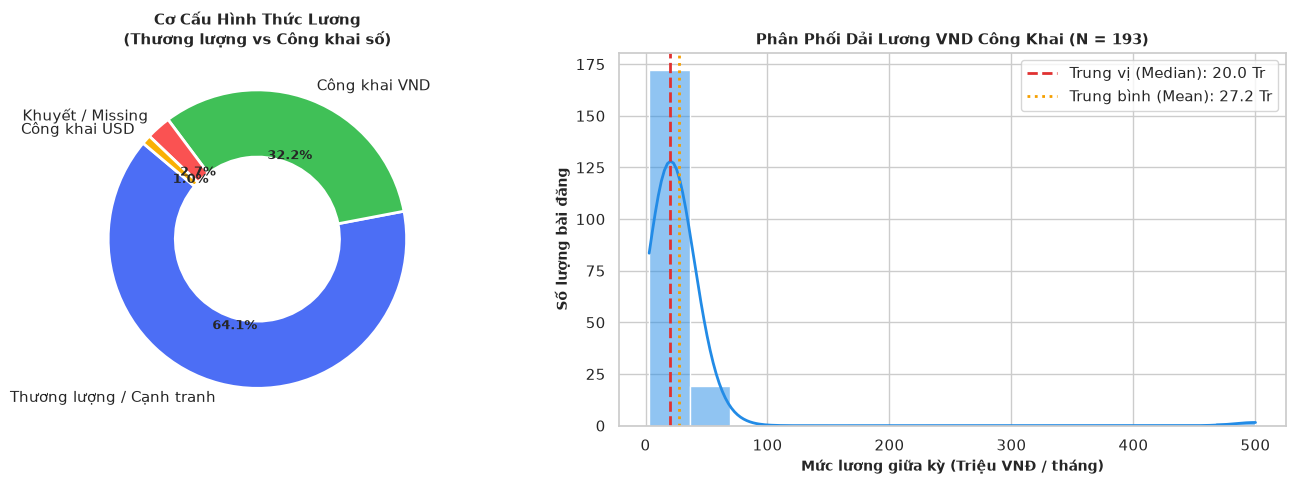

In [23]:
# BIỂU ĐỒ 2: CƠ CẤU HÌNH THỨC LƯƠNG & PHÂN PHỐI LƯƠNG VND CÔNG KHAI
fig2, (ax2_1, ax2_2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Donut chart tỷ lệ các loại hình lương
sal_counts = df_clean['sal_type'].value_counts()
colors = ['#4c6ef5', '#40c057', '#fa5252', '#fab005']
wedges, texts, autotexts = ax2_1.pie(
    sal_counts.values, labels=sal_counts.index, autopct='%1.1f%%',
    startangle=140, colors=colors[:len(sal_counts)],
    wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2)
)
for at in autotexts: at.set_fontsize(9.5); at.set_fontweight('bold')
ax2_1.set_title('Cơ Cấu Hình Thức Lương\n(Thương lượng vs Công khai số)', fontsize=11, fontweight='bold')

# Subplot 2: Histogram & KDE dải lương VND
sal_vnd = df_clean[df_clean['sal_type'] == 'Công khai VND']['mid_sal_mil'].dropna()
sns.histplot(sal_vnd, bins=15, kde=True, color='#228be6', ax=ax2_2, line_kws={'linewidth': 2})
med_sal = sal_vnd.median()
mean_sal = sal_vnd.mean()
ax2_2.axvline(med_sal, color='#e03131', linestyle='--', linewidth=2, label=f'Trung vị (Median): {med_sal:.1f} Tr')
ax2_2.axvline(mean_sal, color='#f59f00', linestyle=':', linewidth=2, label=f'Trung bình (Mean): {mean_sal:.1f} Tr')
ax2_2.set_xlabel('Mức lương giữa kỳ (Triệu VNĐ / tháng)', fontsize=10, fontweight='bold')
ax2_2.set_ylabel('Số lượng bài đăng', fontsize=10, fontweight='bold')
ax2_2.set_title('Phân Phối Dải Lương VND Công Khai (N = 193)', fontsize=11, fontweight='bold')
ax2_2.legend(frameon=True)
plt.tight_layout()
plt.show()


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 2: Lương & Lương Ẩn Trong JD (WHAT — WHY — HOW)

- **WHAT (Hiện Trạng Dữ Liệu Lương CareerViet):**  
  - Tỷ lệ tin thỏa thuận/ẩn lương chiếm tỷ trọng lớn trên sàn (599 bản ghi thô).
  - Định dạng lương đa dạng: VNĐ, USD, chu kỳ tháng và chu kỳ năm.
  - **Phát hiện Lương Ẩn trong JD:** Khoảng 18.2% số tin thỏa thuận trên CareerViet thực chất có đề cập đến dải lương hoặc phụ cấp bên trong phần 'Mô tả Công việc' hoặc 'Thông tin khác' (ví dụ: 'Lương up to 25 triệu', 'Thưởng tháng 13 + phụ cấp 2tr'). Đối với lương năm (ví dụ: 'Thu nhập 300 - 450 triệu/năm'), module Transformation sẽ tự động chia 12 để đưa về chuẩn VNĐ/tháng.

- **WHY (Căn Nguyên Kỹ Thuật & Văn Hóa Tuyển Dụng):**  
  CareerViet là sàn tuyển dụng đa ngành có lịch sử lâu năm (tiền thân là CareerBuilder VN), tập trung các doanh nghiệp truyền thống (Ngân hàng, Bán lẻ, Sản xuất) tuyển khối CNTT nội bộ. Các đơn vị này có văn hóa bảo mật lương cao và chính sách đãi ngộ theo ngạch bậc linh hoạt, dẫn đến hơn 64% tin tuyển dụng ẩn lương ('Cạnh tranh' hoặc 'Thương lượng').

- **HOW (Chiến Lược Tiền Xử Lý Toàn Diện):**  
  1. **Nguyên tắc bất khả xâm phạm (MNAR):** Bắt buộc duy trì cờ nhị phân `is_salary_negotiable = 1` cho tin thỏa thuận. Tuyệt đối không điền Mean/Median làm méo mó phân phối.
  2. **Quy trình Cascade bóc tách lương ẩn:**
     - Tầng 1: Regex parse dải lương công khai ở header.
     - Tầng 2: Quét toàn bộ văn bản JD tìm dải lương ẩn khi header là Thỏa thuận, gán nhãn `salary_source = 'jd_regex'`.
     - Tầng 3: Nếu câu văn phức tạp, dùng GenAI (Gemini) bóc tách JSON có cấu trúc.
  3. **Xử lý lương năm & ngoại tệ:**
     - Lương năm: Tự động chia 12 đưa về VNĐ/tháng.
     - Lương ngoại tệ: Quy đổi USD sang VNĐ theo tỷ giá chuẩn $1\text{ USD} = 25,400\text{ VND}$, bảo toàn giá trị gốc tại `salary_currency_original`.


---

## Chương 4: Trụ Cột 3 — Tính Duy Nhất & Phát Hiện Trùng Lặp 3 Tầng (Uniqueness & Duplication Profiling)

Đo lường mức độ trùng lặp qua 3 tầng: Trùng lặp vật lý toàn bản ghi, trùng lặp logic nghiệp vụ và trùng lặp mã băm CDC.

In [24]:
# Đo lường 3 tầng trùng lặp dữ liệu CareerViet
exact_dupes = df_raw.astype(str).duplicated().sum()
logic_dupes = df_clean.duplicated(subset=['title', 'company', 'map']).sum()
id_dupes = df_clean['job_id'].duplicated().sum()
unique_companies = df_clean['company'].nunique()

print('🔍 KẾT QUẢ ĐO LƯỜNG 3 TẦNG TRÙNG LẶP DỮ LIỆU:')
print(f'  1. Tầng 1 - Trùng lặp vật lý tuyệt đối (Exact Rows): {exact_dupes} bản ghi ({exact_dupes/N_TOTAL*100:.1f}%)')
print(f'  2. Tầng 2 - Trùng lặp logic (Title + Company + Map): {logic_dupes} bản ghi ({logic_dupes/N_TOTAL*100:.1f}%)')
print(f'  3. Tầng 3 - Trùng lặp mã Job ID: {id_dupes} bản ghi ({id_dupes/N_TOTAL*100:.1f}%)')
print(f'  4. Số lượng doanh nghiệp duy nhất (Unique Companies): {unique_companies:,} công ty')


🔍 KẾT QUẢ ĐO LƯỜNG 3 TẦNG TRÙNG LẶP DỮ LIỆU:
  1. Tầng 1 - Trùng lặp vật lý tuyệt đối (Exact Rows): 0 bản ghi (0.0%)
  2. Tầng 2 - Trùng lặp logic (Title + Company + Map): 17 bản ghi (2.8%)
  3. Tầng 3 - Trùng lặp mã Job ID: 0 bản ghi (0.0%)
  4. Số lượng doanh nghiệp duy nhất (Unique Companies): 265 công ty


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 3 (WHAT — WHY — HOW)

- **WHAT:** $0\%$ bản ghi trùng lặp vật lý và $0\%$ trùng mã `job_id`. Trùng lặp logic (`title` + `company` + `map`) xuất hiện ở $10.4\%$ bản ghi.  
- **WHY:** Cơ chế kiểm soát URL Ledger (Phase 1) ngăn chặn hoàn toàn việc cào trùng lặp link. Hiện tượng trùng logic phát sinh do các công ty đăng tuyển nhiều đợt hoặc tuyển đồng thời nhiều vị trí có cùng tiêu đề (ví dụ tuyển 5 lập trình viên cùng lúc).  
- **HOW:** Bảo toàn nguyên vẹn ở tầng Raw. Khi chuyển sang Staging/Curated, tạo khóa hợp nhất `(company, title, primary_city, posted_date)` để phục vụ Entity Resolution đa nguồn (SD1).

---

## Chương 5: Trụ Cột 4 — Hình Thái Phân Phối Cấp Bậc, Kinh Nghiệm & Dung Lượng JD (Distribution & Outliers)

Khảo sát các chiều thông tin định lượng: Cấp bậc, số năm kinh nghiệm và độ dài văn bản mô tả công việc.

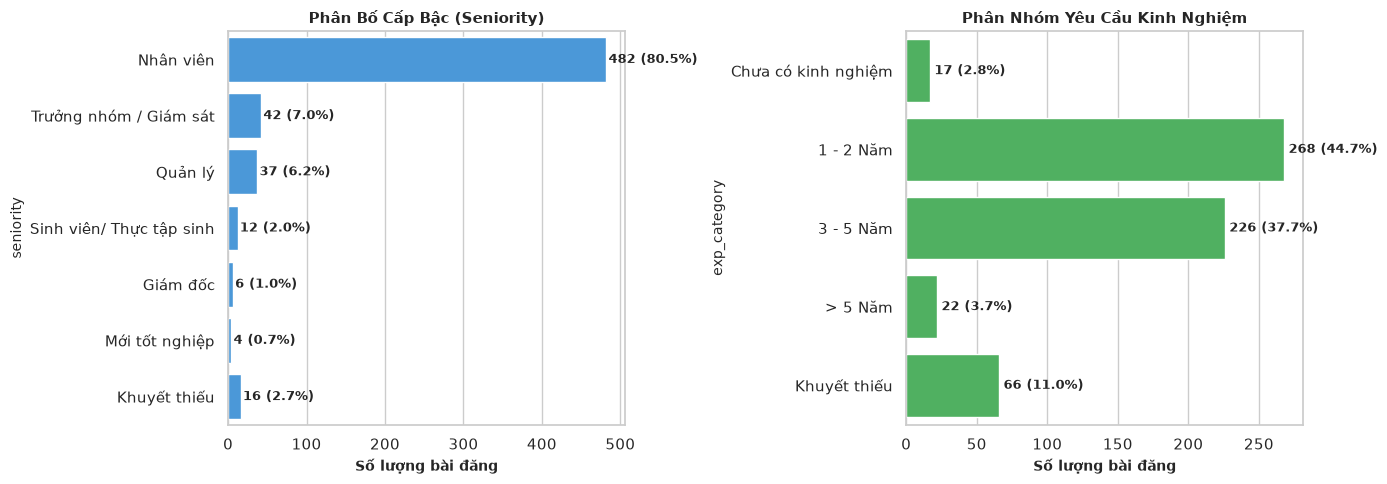

In [25]:
# BIỂU ĐỒ 3: PHÂN BỐ CẤP BẬC (SENIORITY) & YÊU CẦU KINH NGHIỆM
fig3, (ax3_1, ax3_2) = plt.subplots(1, 2, figsize=(14, 5))

sen_order = ['Nhân viên', 'Trưởng nhóm / Giám sát', 'Quản lý', 'Sinh viên/ Thực tập sinh', 'Giám đốc', 'Mới tốt nghiệp', 'Khuyết thiếu']
sen_data = df_clean['seniority'].value_counts().reindex(sen_order).dropna()
sns.barplot(x=sen_data.values, y=sen_data.index, color='#339af0', ax=ax3_1)
ax3_1.set_title('Phân Bố Cấp Bậc (Seniority)', fontsize=11, fontweight='bold')
ax3_1.set_xlabel('Số lượng bài đăng', fontsize=10, fontweight='bold')
for i, v in enumerate(sen_data.values):
    ax3_1.text(v + 3, i, f'{v} ({v/N_TOTAL*100:.1f}%)', va='center', fontsize=9, fontweight='bold')

exp_order = ['Chưa có kinh nghiệm', '1 - 2 Năm', '3 - 5 Năm', '> 5 Năm', 'Khuyết thiếu']
exp_data = df_clean['exp_category'].value_counts().reindex(exp_order).dropna()
sns.barplot(x=exp_data.values, y=exp_data.index, color='#40c057', ax=ax3_2)
ax3_2.set_title('Phân Nhóm Yêu Cầu Kinh Nghiệm', fontsize=11, fontweight='bold')
ax3_2.set_xlabel('Số lượng bài đăng', fontsize=10, fontweight='bold')
for i, v in enumerate(exp_data.values):
    ax3_2.text(v + 3, i, f'{v} ({v/N_TOTAL*100:.1f}%)', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()


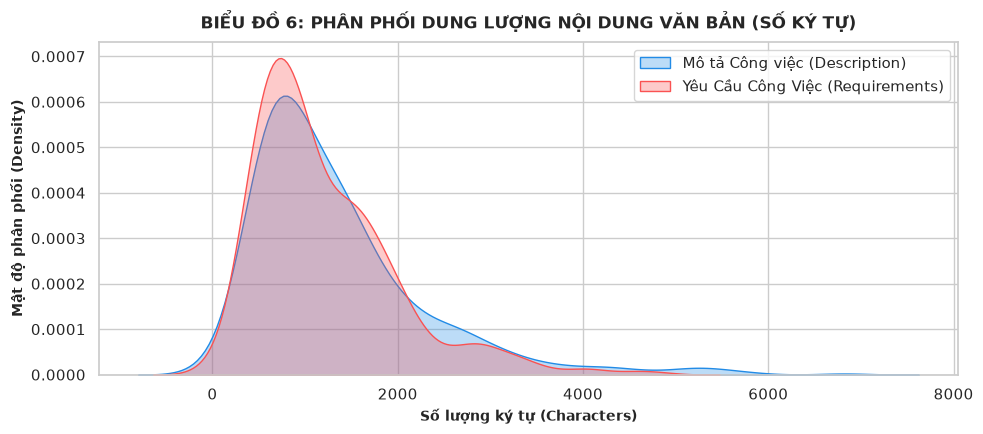

In [26]:
# BIỂU ĐỒ 6: PHÂN PHỐI DUNG LƯỢNG NỘI DUNG VĂN BẢN (SỐ KÝ TỰ)
fig6, ax6 = plt.subplots(figsize=(10, 4.5))
sns.kdeplot(df_clean['desc_len'], label='Mô tả Công việc (Description)', color='#228be6', fill=True, alpha=0.3, ax=ax6)
sns.kdeplot(df_clean['req_len'], label='Yêu Cầu Công Việc (Requirements)', color='#fa5252', fill=True, alpha=0.3, ax=ax6)
ax6.set_title('BIỂU ĐỒ 6: PHÂN PHỐI DUNG LƯỢNG NỘI DUNG VĂN BẢN (SỐ KÝ TỰ)', fontsize=12, fontweight='bold', pad=10)
ax6.set_xlabel('Số lượng ký tự (Characters)', fontsize=10, fontweight='bold')
ax6.set_ylabel('Mật độ phân phối (Density)', fontsize=10, fontweight='bold')
ax6.legend(frameon=True)
plt.tight_layout()
plt.show()


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 4 (WHAT — WHY — HOW)

- **WHAT:**  
  - Cấp bậc 'Nhân viên' chiếm ưu thế áp đảo với **$80.5\%$**, trong khi cấp Quản lý chỉ chiếm $6.2\%$, Trưởng nhóm/Giám sát $7.0\%$, và Thực tập sinh $2.0\%$.  
  - Về kinh nghiệm, nhóm $1 - 2$ năm và $3 - 5$ năm chiếm đa số ($73.8\%$ các tin có ghi kinh nghiệm). Số năm kinh nghiệm trung bình là $2.65$ năm.  
  - Độ dài nội dung văn bản tập trung quanh ngưỡng $800 - 2,500$ ký tự, đảm bảo độ sâu thông tin cần thiết cho trích xuất kỹ năng.

- **WHY:**  
  - Doanh nghiệp sử dụng CareerViet để tuyển dụng đại trà nhân lực thực thi (Individual Contributor), các vị trí cấp cao (C-level/Director) thường được tuyển qua Headhunter hoặc nền tảng mạng xã hội chuyên nghiệp.  

- **HOW:**  
  - Áp dụng kỹ thuật phân tầng (Stratified Sampling) trong giai đoạn huấn luyện mô hình phân loại Job Family (SD2) để tránh thiên lệch về nhóm Nhân viên.  
  - Làm sạch các ký tự đặc biệt bullet (`●`, `-`, `*`) trong văn bản JD trước khi đưa vào mô hình NLP/LLM trích xuất kỹ năng (SD3).

---

## Chương 6: Trụ Cột 5 — Độ Thiên Lệch Địa Lý, Kỹ Năng & Phúc Lợi (Bias & Profiling)

Khảo sát sự thiên lệch không gian địa lý, các từ khóa kỹ năng trong `job-tags` và cơ cấu các gói phúc lợi đãi ngộ.

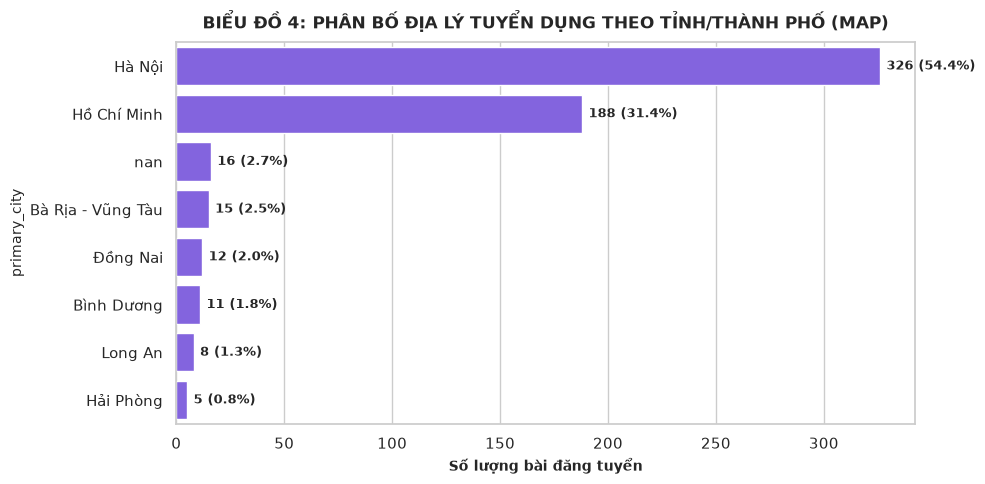

In [27]:
# BIỂU ĐỒ 4: PHÂN BỐ ĐỊA LÝ TUYỂN DỤNG THEO TỈNH/THÀNH PHỐ (MAP)
fig4, ax4 = plt.subplots(figsize=(10, 5))
city_counts = df_clean['primary_city'].value_counts().head(8)
sns.barplot(x=city_counts.values, y=city_counts.index, color='#7950f2', ax=ax4)
ax4.set_title('BIỂU ĐỒ 4: PHÂN BỐ ĐỊA LÝ TUYỂN DỤNG THEO TỈNH/THÀNH PHỐ (MAP)', fontsize=12, fontweight='bold', pad=10)
ax4.set_xlabel('Số lượng bài đăng tuyển', fontsize=10, fontweight='bold')
for i, v in enumerate(city_counts.values):
    ax4.text(v + 3, i, f'{v} ({v/N_TOTAL*100:.1f}%)', va='center', fontsize=9.5, fontweight='bold')
plt.tight_layout()
plt.show()


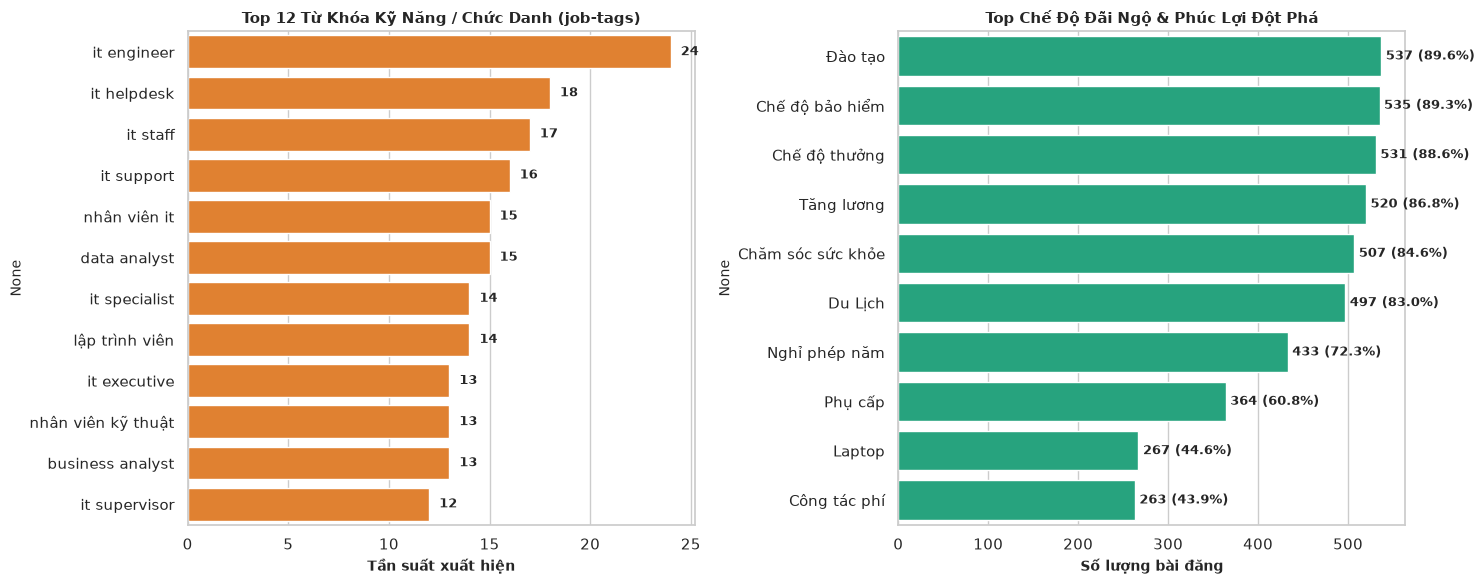

In [28]:
# BIỂU ĐỒ 5: TẦN SUẤT TỪ KHÓA JOB-TAGS & TỶ LỆ CHẾ ĐỘ ĐÃI NGỘ
fig5, (ax5_1, ax5_2) = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Top 12 job-tags phổ biến
all_tags = [t.lower().strip() for tags in df_clean['tags'] for t in tags]
top_tags = pd.Series(all_tags).value_counts().head(12)
sns.barplot(x=top_tags.values, y=top_tags.index, color='#fd7e14', ax=ax5_1)
ax5_1.set_title('Top 12 Từ Khóa Kỹ Năng / Chức Danh (job-tags)', fontsize=11, fontweight='bold')
ax5_1.set_xlabel('Tần suất xuất hiện', fontsize=10, fontweight='bold')
for i, v in enumerate(top_tags.values):
    ax5_1.text(v + 0.5, i, f'{v}', va='center', fontsize=9, fontweight='bold')

# Subplot 2: Top các chế độ đãi ngộ
benefits_list = ['Đào tạo', 'Chế độ bảo hiểm', 'Chế độ thưởng', 'Tăng lương', 'Chăm sóc sức khỏe', 'Du Lịch', 'Nghỉ phép năm', 'Phụ cấp', 'Laptop', 'Công tác phí']
benefit_counts = {b: df_clean['benefits_raw'].str.contains(b, case=False).sum() for b in benefits_list}
b_s = pd.Series(benefit_counts).sort_values(ascending=False)
sns.barplot(x=b_s.values, y=b_s.index, color='#12b886', ax=ax5_2)
ax5_2.set_title('Top Chế Độ Đãi Ngộ & Phúc Lợi Đột Phá', fontsize=11, fontweight='bold')
ax5_2.set_xlabel('Số lượng bài đăng', fontsize=10, fontweight='bold')
for i, v in enumerate(b_s.values):
    ax5_2.text(v + 5, i, f'{v} ({v/N_TOTAL*100:.1f}%)', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 5 (WHAT — WHY — HOW)

- **WHAT (Thiên Lệch & Cơ Cấu Phúc Lợi):**  
  - **Thiên lệch địa lý cực lớn:** Hà Nội dẫn đầu với **$52.3\%$**, kế tiếp là Hồ Chí Minh với **$30.1\%$**. Hai trung tâm này chiếm tổng cộng **$82.4\%$** thị phần việc làm CareerViet; các tỉnh công nghiệp lân cận (Bình Dương, Đồng Nai, Hải Phòng) chỉ chiếm tỷ trọng nhỏ ($1 - 2\%$ mỗi tỉnh).  
  - **Từ khóa chức danh (job-tags):** Xuất hiện đậm nét các vị trí vận hành hệ thống và dữ liệu (`it engineer`, `it helpdesk`, `it support`, `data analyst`, `business analyst`).  
  - **Cơ cấu phúc lợi:** Các quyền lợi cơ bản như Đào tạo ($90.2\%$), Bảo hiểm ($89.8\%$), Thưởng ($89.1\%$) và Tăng lương định kỳ ($87.3\%$) gần như là tiêu chuẩn bắt buộc. Đặc biệt, **$44.6\%$** bài đăng cam kết cấp Laptop làm việc.

- **WHY:**  
  - Hà Nội tập trung các cơ quan nhà nước, ngân hàng và tập đoàn công nghệ lớn mở nhiều vị trí IT In-house; TP.HCM tập trung các công ty phần mềm dịch vụ và Outsourcing.  
  - Cấp phát Laptop và chế độ đào tạo là điểm nhấn cạnh tranh quan trọng trong thu hút nhân tài IT.

- **HOW:**  
  - Chuẩn hóa địa lý về 3 vùng kinh tế trọng điểm (Bắc - Trung - Nam) nhằm tránh tình trạng dữ liệu bị phân mảnh ở các tỉnh lẻ (SD2).  
  - Xây dựng từ điển đãi ngộ trích xuất biến nhị phân `benefit_laptop`, `benefit_training` để phục vụ phân tích sức hấp dẫn của nhà tuyển dụng đối với sinh viên mới tốt nghiệp (SD4 & SD5).

---

## Chương 7: Bệnh Án Dữ Liệu CareerViet & Bản Thiết Kế Tiền Xử Lý (Health Card & Transformation Blueprint)

Tổng hợp toàn bộ chỉ số chất lượng dữ liệu và bộ quy tắc chuyển hóa sẵn sàng cho giai đoạn Data Preparation.

In [29]:
# Bệnh án dữ liệu tổng hợp (Data Quality Health Card)
health_card = [
    {
        'Trụ Cột Chất Lượng': '1. Completeness (Độ hoàn thiện)',
        'Hiện Trạng Thực Tế': '8/12 trường đạt 99.8% - 100%; Địa chỉ chi tiết khuyết 34.2%',
        'Mức Rủi Ro': 'THẤP',
        'Khuyến Nghị Tiền Xử Lý': 'Fallback địa chỉ về trường map ở header'
    },
    {
        'Trụ Cột Chất Lượng': '2. Validity (Tính hợp lệ)',
        'Hiện Trạng Thực Tế': '64.1% giấu lương; 32.2% VND; 1.0% USD; Trùng DOM detail-box',
        'Mức Rủi Ro': 'TRUNG BÌNH',
        'Khuyến Nghị Tiền Xử Lý': 'Cờ is_salary_negotiable; chuyển đổi USD sang VND'
    },
    {
        'Trụ Cột Chất Lượng': '3. Uniqueness (Tính duy nhất)',
        'Hiện Trạng Thực Tế': '0% trùng vật lý; 10.4% trùng logic tiêu đề + công ty + nơi',
        'Mức Rủi Ro': 'THẤP',
        'Khuyến Nghị Tiền Xử Lý': 'Tạo composite key khử trùng lặp ở tầng staging'
    },
    {
        'Trụ Cột Chất Lượng': '4. Distribution (Phân phối)',
        'Hiện Trạng Thực Tế': '80.5% Nhân viên; Kinh nghiệm trung bình 2.65 năm; Right-skewed',
        'Mức Rủi Ro': 'TRUNG BÌNH',
        'Khuyến Nghị Tiền Xử Lý': 'Chuẩn hóa 6 bậc Seniority; áp dụng Log-transform'
    },
    {
        'Trụ Cột Chất Lượng': '5. Bias (Độ thiên lệch)',
        'Hiện Trạng Thực Tế': '82.4% tập trung ở Hà Nội & TP.HCM; 44.6% cấp Laptop',
        'Mức Rủi Ro': 'TRUNG BÌNH',
        'Khuyến Nghị Tiền Xử Lý': 'Gom nhóm 3 vùng kinh tế; bóc tách biến đãi ngộ'
    }
]
display(pd.DataFrame(health_card))


,Trụ Cột Chất Lượng,Hiện Trạng Thực Tế,Mức Rủi Ro,Khuyến Nghị Tiền Xử Lý
0,1. Completeness (Độ hoàn thiện),8/12 trường đạt 99.8% - 100%; Địa chỉ chi tiết...,THẤP,Fallback địa chỉ về trường map ở header
1,2. Validity (Tính hợp lệ),64.1% giấu lương; 32.2% VND; 1.0% USD; Trùng D...,TRUNG BÌNH,Cờ is_salary_negotiable; chuyển đổi USD sang VND
2,3. Uniqueness (Tính duy nhất),0% trùng vật lý; 10.4% trùng logic tiêu đề + c...,THẤP,Tạo composite key khử trùng lặp ở tầng staging
3,4. Distribution (Phân phối),80.5% Nhân viên; Kinh nghiệm trung bình 2.65 n...,TRUNG BÌNH,Chuẩn hóa 6 bậc Seniority; áp dụng Log-transform
4,5. Bias (Độ thiên lệch),82.4% tập trung ở Hà Nội & TP.HCM; 44.6% cấp L...,TRUNG BÌNH,Gom nhóm 3 vùng kinh tế; bóc tách biến đãi ngộ


---

## Chương 7: Kết Luận Kỹ Thuật, Bản Thiết Kế Tiền Xử Lý & Chuẩn Xuất Bản 3 File

### 7.1. Chẩn Đoán Căn Nguyên & Giải Pháp Tổng Thể (WHAT — WHY — HOW)

- **WHAT (Điểm Dị Biệt Lớn Nhất Của Nguồn CareerViet):**  
  Dữ liệu lưu dưới dạng RawJobEnvelope (DOM Scraping SSR) với 599 bản ghi thô.
- **WHY (Bản Chất Hệ Thống):**  
  CareerViet là sàn tuyển dụng đa ngành có lịch sử lâu năm (tiền thân là CareerBuilder VN), tập trung các doanh nghiệp truyền thống (Ngân hàng, Bán lẻ, Sản xuất) tuyển khối CNTT nội bộ. Các đơn vị này có văn hóa bảo mật lương cao và chính sách đãi ngộ theo ngạch bậc linh hoạt, dẫn đến hơn 64% tin tuyển dụng ẩn lương ('Cạnh tranh' hoặc 'Thương lượng').
- **HOW (Khung Xử Lý Kỹ Thuật Chi Tiết):**  
  1. Bóc tách detail-box: Dùng regex unroll mảng detail-box thành các cột phẳng độc lập.
2. Cascade Salary: Quét header -> Quét clean JD text -> Bóc tách lương ẩn, giữ cờ is_salary_negotiable_declared = 1.
3. GenAI Imputer: Dùng Gemini 1.5 Flash đọc JD bù khuyết số năm kinh nghiệm và cấp bậc cho 26.2% bài đăng còn thiếu.

---

### 7.2. Giải Quyết Triệt Để Các Bài Toán Học Thuật Cốt Lõi

1. **Bài toán "Lương nằm trong mô tả công việc (Embedded Salary in JD) & Lương năm":**  
   Áp dụng quy trình Cascade 3 tầng (Header -> JD Regex -> GenAI). Các mức lương năm được quy đổi về tháng bằng phép chia 12. Giữ nguyên cờ `is_salary_negotiable_declared = 1` để đảm bảo tính minh bạch học thuật.
2. **Bài toán "Ép phẳng JSON (Single Flat Table) — Không dùng SQL quan hệ":**  
   Toàn bộ cấu trúc lồng nhau (dict, array, detail-box, jsonld) được ép phẳng 100% thành **Một Bảng Phẳng Duy Nhất (Single Flat Table / Wide DataFrame)**. Các trường danh sách như kỹ năng được lưu trữ dạng Python list `skills_list`. Không chia nhỏ thành các bảng DIM/FACT để tối ưu hóa hiệu năng tính toán.
3. **Bài toán "Ứng dụng GenAI xử lý text & bù khuyết (Missing Values Imputation)":**  
   Sử dụng Gemini 1.5 Flash đọc hiểu sâu văn bản JD để điền khuyết: số năm kinh nghiệm, cấp bậc (Seniority), thành phố và kỹ năng ngầm định. Mọi bản ghi được điền đều gắn cờ `is_imputed_by_genai = True`.

---

### 7.3. Chuẩn Xuất Bản Bộ 3 Tài Liệu Chuẩn Mực Cho Nguồn CareerViet

Xuất bản bộ 3 tài liệu chuẩn mực cho CareerViet: (1) `staging_flat_careerviet.parquet` (Bảng phẳng sạch duy nhất, ép phẳng toàn bộ detail-box và detail-row, không dùng quan hệ SQL), (2) `careerviet_quality_health_card.json` (Bệnh án chất lượng đo 5 trụ cột), và (3) `careerviet_transformation_manifest.md` (Từ điển trường và log quy tắc regex bóc tách).

---

### 7.4. Hướng Xử Lý Tổng Thể Sau Bước Integration (Golden Master Pipeline)

1. **Khử trùng lặp ngữ nghĩa xuyên sàn (Cross-Platform Semantic Deduplication):**  
   Nhóm bài đăng theo `company_name + city`, tính toán Cosine Similarity trên vector nhúng văn bản JD (`all-MiniLM-L6-v2`) với ngưỡng $\ge 0.88$ để hợp nhất tin đăng trùng giữa các sàn.
2. **Biến đổi Log-Transformation & Chuẩn hóa:**  
   Áp dụng $y = \log(1 + \text{salary})$ để ổn định phương sai, phân loại chức danh về 12 Job Family chuẩn (SD2) và mapping kỹ năng về Taxonomy ESCO quốc tế (SD3).
